# Machine Learning Classification Assignment

Ready-to-run notebook for Questions 1–4.

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay

Matplotlib is building the font cache; this may take a moment.


## Question 1 — Random Forest: Breast Cancer

Shape: (569, 30)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}
Missing values: 0
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1: 0.9655172413793104
ROC-AUC: 0.9937169312169312

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



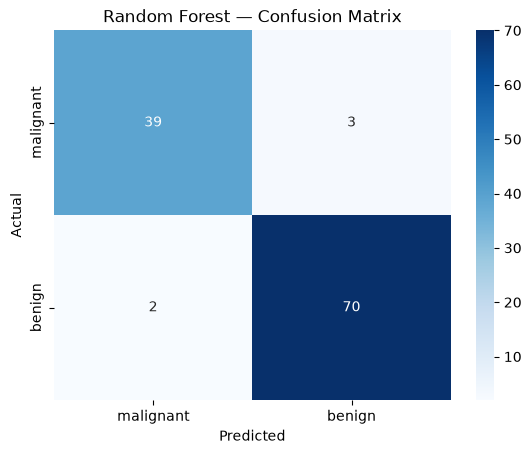

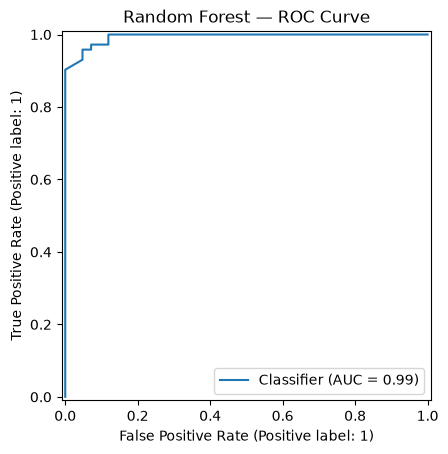

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Shape:", X.shape)
print("Classes:", dict(enumerate(data.target_names)))
print("Missing values:", X.isnull().sum().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
prob = rf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, prob))
print("\nClassification Report:")
print(classification_report(y_test, pred, target_names=data.target_names))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Random Forest — Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, prob)
plt.title("Random Forest — ROC Curve")
plt.show()

## Question 2 — Logistic Regression: Pima Indians Diabetes

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Missing values after zero handling:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Accuracy: 0.7077922077922078
Precision: 0.6
Recall: 0.5
F1: 0.5454545454545454
ROC-AUC: 0.812962962962963

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



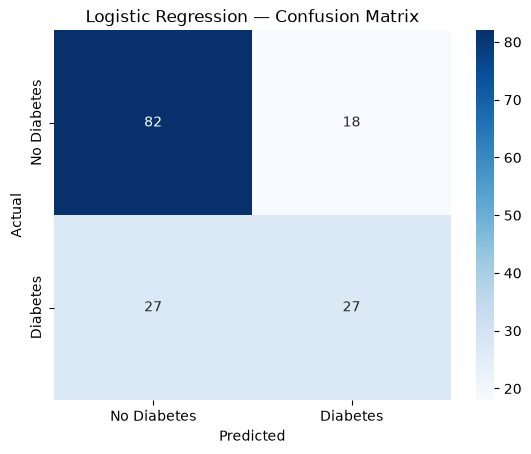

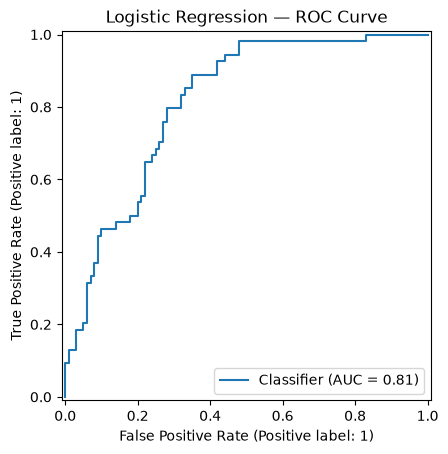

,Feature,Coefficient,Absolute_Coefficient
1,Glucose,1.182511,1.182511
5,BMI,0.688735,0.688735
0,Pregnancies,0.377502,0.377502
6,DiabetesPedigreeFunction,0.233386,0.233386
7,Age,0.147798,0.147798
4,Insulin,-0.066157,0.066157
2,BloodPressure,-0.044066,0.044066
3,SkinThickness,0.028225,0.028225


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin",
           "BMI","DiabetesPedigreeFunction","Age","Outcome"]

diabetes = pd.read_csv(url, names=columns)
print("Shape:", diabetes.shape)
display(diabetes.head())

zero_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
diabetes[zero_cols] = diabetes[zero_cols].replace(0, np.nan)

print("Missing values after zero handling:")
display(diabetes.isnull().sum())

for c in zero_cols:
    diabetes[c] = diabetes[c].fillna(diabetes[c].median())

X = diabetes.drop("Outcome", axis=1)
y = diabetes["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)

pred = lr.predict(X_test_s)
prob = lr.predict_proba(X_test_s)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, prob))
print("\nClassification Report:")
print(classification_report(y_test, pred))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Diabetes","Diabetes"],
            yticklabels=["No Diabetes","Diabetes"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, prob)
plt.title("Logistic Regression — ROC Curve")
plt.show()

coef = pd.DataFrame({"Feature": X.columns, "Coefficient": lr.coef_[0]})
coef["Absolute_Coefficient"] = coef["Coefficient"].abs()
display(coef.sort_values("Absolute_Coefficient", ascending=False))

## Question 3 — XGBoost: Titanic Survival

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Parameters: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 4, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 100, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}

Accuracy: 0.7877094972067039
Precision: 0.7719298245614035
Recall: 

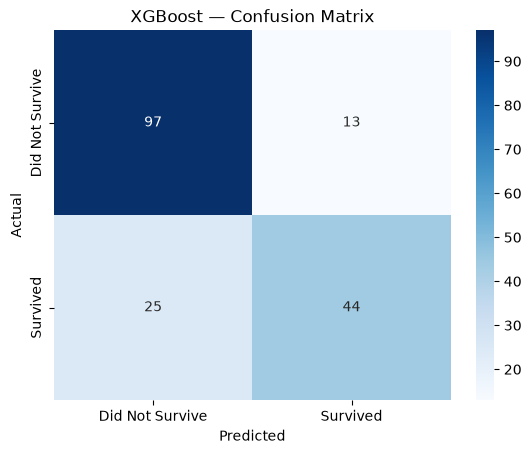

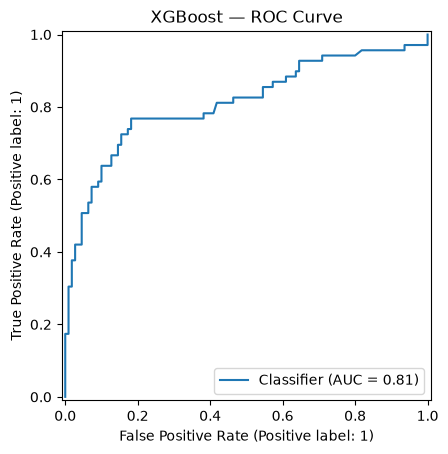

,Feature,Importance
5,Sex_male,0.451286
0,Pclass,0.178971
6,Embarked_Q,0.084881
2,SibSp,0.069376
1,Age,0.062053
4,Fare,0.056640
7,Embarked_S,0.053062
3,Parch,0.043731


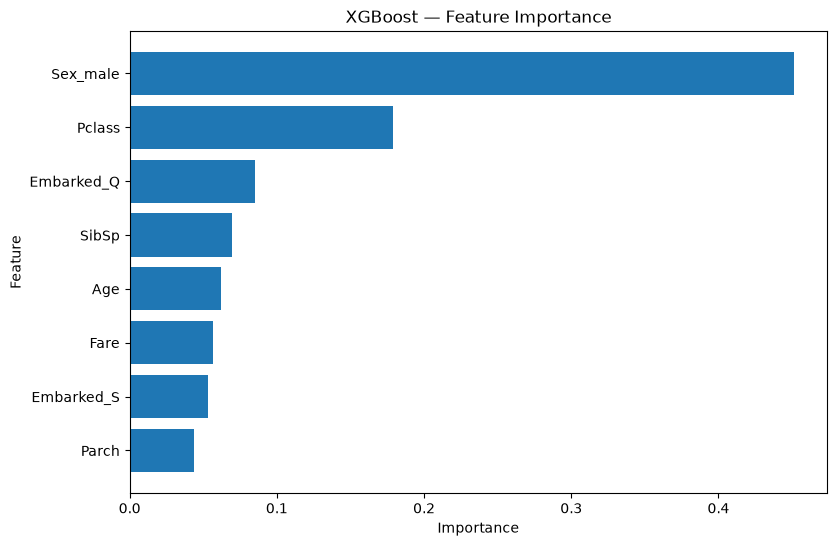

In [5]:
from xgboost import XGBClassifier

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

print("Shape:", titanic.shape)
display(titanic.head())
display(titanic.isnull().sum())

features = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]
X = titanic[features].copy()
y = titanic["Survived"].astype(int)

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())
X["Embarked"] = X["Embarked"].fillna(X["Embarked"].mode()[0])

X = pd.get_dummies(X, columns=["Sex","Embarked"], drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)
pred = xgb.predict(X_test)
prob = xgb.predict_proba(X_test)[:, 1]

print("Parameters:", xgb.get_params())
print("\nAccuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, prob))
print("\nClassification Report:")
print(classification_report(y_test, pred))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Did Not Survive","Survived"],
            yticklabels=["Did Not Survive","Survived"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("XGBoost — Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, prob)
plt.title("XGBoost — ROC Curve")
plt.show()

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)
plt.figure(figsize=(9,6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.title("XGBoost — Feature Importance")
plt.gca().invert_yaxis()
plt.show()

## Question 4 — Decision Tree: Pima Indians Diabetes

Original Decision Tree
Accuracy: 0.6818181818181818
Precision: 0.5531914893617021
Recall: 0.48148148148148145
F1: 0.5148514851485149

Confusion Matrix:
[[79 21]
 [28 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       100
           1       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154



,Metric,Original Tree,Restricted Tree (max_depth=3)
0,Accuracy,0.681818,0.688312
1,Precision,0.553191,0.636364
2,Recall,0.481481,0.259259
3,F1-score,0.514851,0.368421


,Feature,Importance
1,Glucose,0.355518
5,BMI,0.178572
7,Age,0.127095
2,BloodPressure,0.097661
6,DiabetesPedigreeFunction,0.092002
4,Insulin,0.069723
0,Pregnancies,0.064105
3,SkinThickness,0.015325


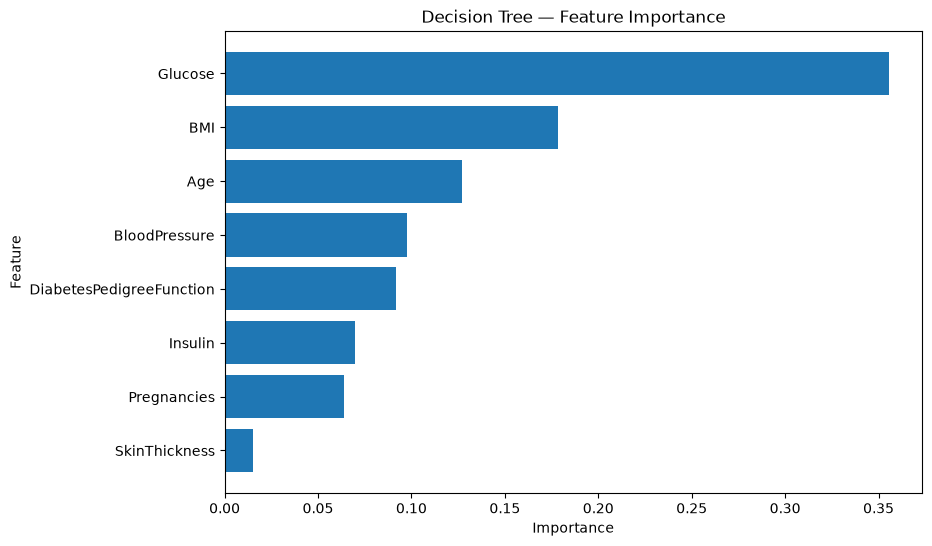

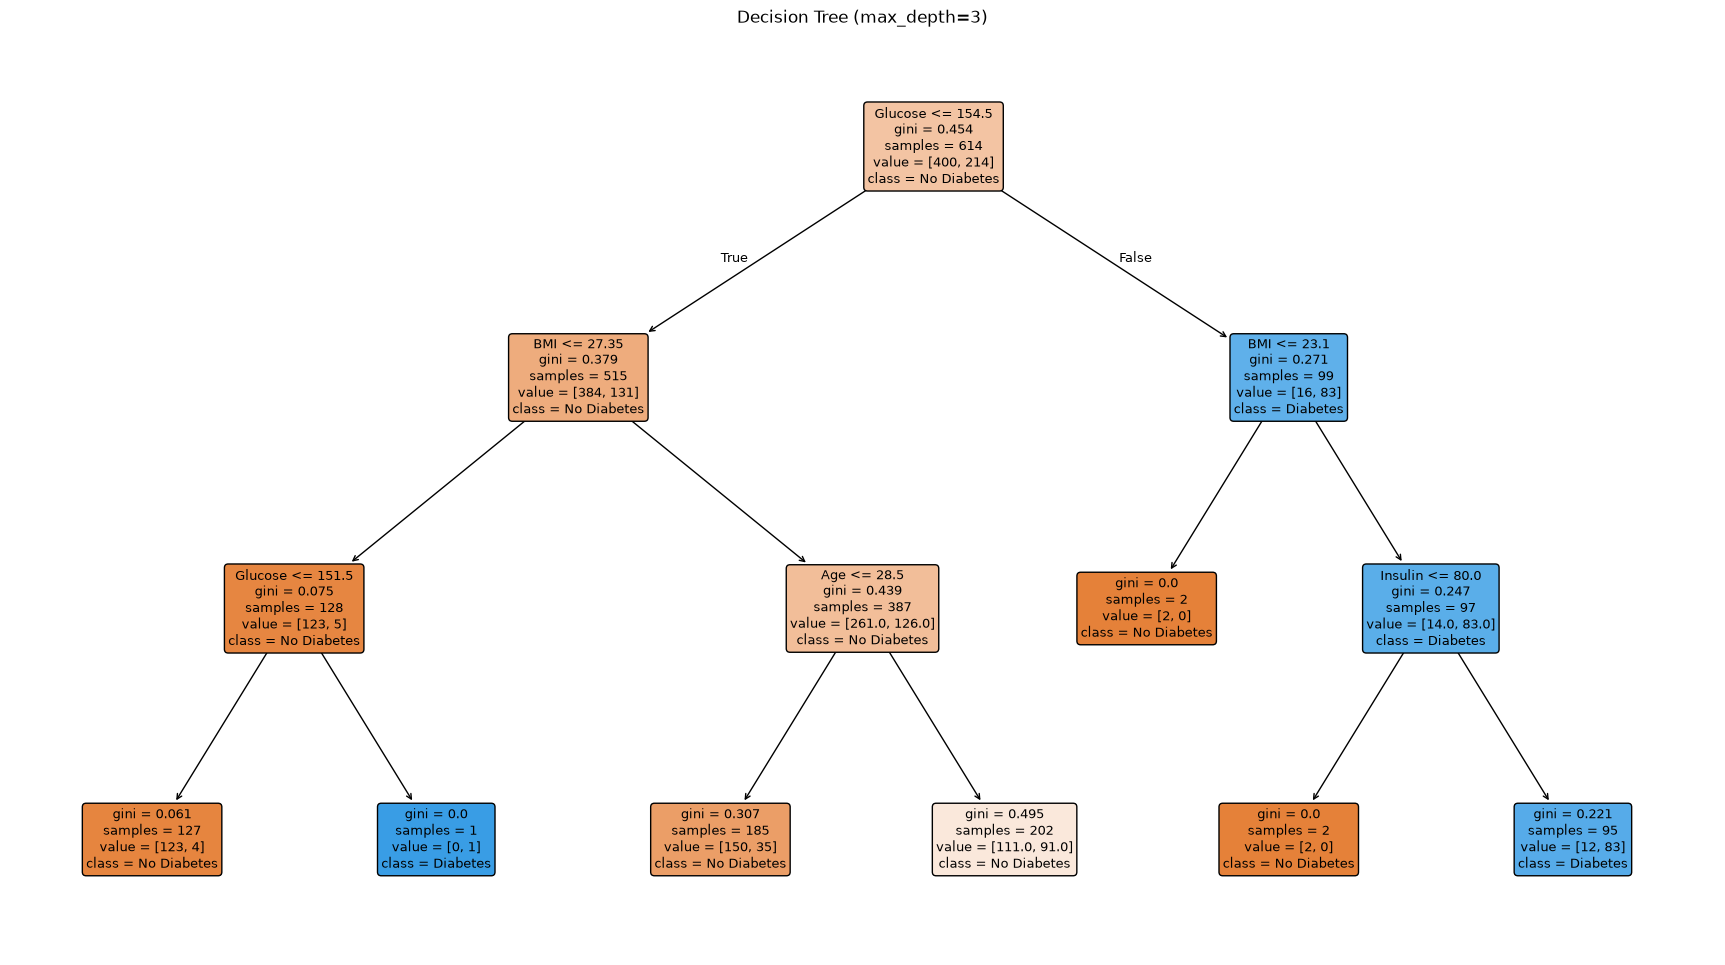

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Use the cleaned Pima dataset from Question 2.
X = diabetes.drop("Outcome", axis=1)
y = diabetes["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
pred = dt.predict(X_test)

print("Original Decision Tree")
print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred))
print("\nClassification Report:")
print(classification_report(y_test, pred))

restricted = DecisionTreeClassifier(max_depth=3, random_state=42)
restricted.fit(X_train, y_train)
restricted_pred = restricted.predict(X_test)

comparison = pd.DataFrame({
    "Metric": ["Accuracy","Precision","Recall","F1-score"],
    "Original Tree": [
        accuracy_score(y_test,pred),
        precision_score(y_test,pred),
        recall_score(y_test,pred),
        f1_score(y_test,pred)
    ],
    "Restricted Tree (max_depth=3)": [
        accuracy_score(y_test,restricted_pred),
        precision_score(y_test,restricted_pred),
        recall_score(y_test,restricted_pred),
        f1_score(y_test,restricted_pred)
    ]
})
display(comparison)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt.feature_importances_
}).sort_values("Importance", ascending=False)
display(importance)

plt.figure(figsize=(9,6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.title("Decision Tree — Feature Importance")
plt.gca().invert_yaxis()
plt.show()

plt.figure(figsize=(22,12))
plot_tree(restricted, feature_names=X.columns,
          class_names=["No Diabetes","Diabetes"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3)")
plt.show()

## Final Summary

All four classification tasks have been implemented and evaluated. Run all cells from top to bottom before submitting the notebook.